<table>
    <tr>
        <td style="text-align:left">
            <img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR9ItLTT_F-3Q30cu7ZCCoKmuFGBt22pe7pNA" alt="Logo Universidad" width="300"/>
        </td>
        <td>
            Departamento de Ciencias de la Computación y de la Decisión<br>
            Facultad de Minas<br>
            Universidad Nacional de Colombia<br>
            Optimizacion e IA 2026-2S<br><br>
            Docente: Maria Constanza Torres Madronero<br>
            <br>
            Contribuciones a la guia por: <br>
            - Deimer Miranda Montoya (2023)<br>
            - Luis Fernando Becerra Monsalve (2024)
        </td>    
    </tr>
</table>

# **Gradiente Descendiente Paso a Paso**






#### (a) Implementacion de gradiente descendiente para minimizar una funcion

In [4]:
#Importacion de librerias
import numpy as np
from matplotlib import pyplot

In [52]:
#Algoritmo de gradiente descendente

def gradiente_descendente(objetivo, derivada, bounds, n_iter, step_size, my_flag):
    # Guardamos las soluciones en una lista
    solutions, score = list(), list()
    max_val = bounds[:, 1]
    min_val = bounds[:, 0]
    
    # Generamos el punto inicial de forma aleatoria
    X_t = min_val + np.random.rand(len(bounds)) * (max_val - min_val)

    # Algoritmo iterativo
    for i in range(n_iter):
      #1. Calculo del gradiente p_{t} = derivada(f(X_t))
      grad = derivada(X_t)
      #2. Actualizacion de la solucion   x_{t+1} = x_{t} - a * p_{t}
      X_t = X_t - step_size * grad
      #3. Evaluacion de la solucion f(X_t) 
      solution_eval = objetivo(X_t)
      #Almacenamos la solucion
      solutions.append(X_t)
      score.append(solution_eval)
      #Mostramos el progreso
      if my_flag:
        print('>%d f(%s) = %.5f' % (i, X_t[0], solution_eval[0]))
      
    return [solutions, score]

In [53]:
#Definimos la funcion objetivo
def objetivo(x):
  return x**2.0

#Calculamos el gradiente de la funcion
def derivada(x):
  return 2 * x


In [57]:
# Deliminatos el rango de los datos
bounds = np.asarray([[-1.0, 1.0]])

# Definimos el numero de iteraciones
n_iter = 50

# Seleccionamos la longitud del paso
step_size = 0.1

# Aplicamos el algoritmo de gradiente descendente
solutions, score = gradiente_descendente(objetivo, derivada, bounds, n_iter, step_size, True)


>0 f(0.6430306148391537) = 0.41349
>1 f(0.514424491871323) = 0.26463
>2 f(0.4115395934970584) = 0.16936
>3 f(0.3292316747976467) = 0.10839
>4 f(0.26338533983811735) = 0.06937
>5 f(0.21070827187049387) = 0.04440
>6 f(0.1685666174963951) = 0.02841
>7 f(0.13485329399711607) = 0.01819
>8 f(0.10788263519769285) = 0.01164
>9 f(0.08630610815815429) = 0.00745
>10 f(0.06904488652652344) = 0.00477
>11 f(0.05523590922121875) = 0.00305
>12 f(0.044188727376975004) = 0.00195
>13 f(0.03535098190158) = 0.00125
>14 f(0.028280785521264) = 0.00080
>15 f(0.0226246284170112) = 0.00051
>16 f(0.01809970273360896) = 0.00033
>17 f(0.014479762186887169) = 0.00021
>18 f(0.011583809749509736) = 0.00013
>19 f(0.009267047799607788) = 0.00009
>20 f(0.007413638239686231) = 0.00005
>21 f(0.005930910591748985) = 0.00004
>22 f(0.004744728473399188) = 0.00002
>23 f(0.0037957827787193504) = 0.00001
>24 f(0.0030366262229754803) = 0.00001
>25 f(0.002429300978380384) = 0.00001
>26 f(0.0019434407827043075) = 0.00000
>27 f(0.0

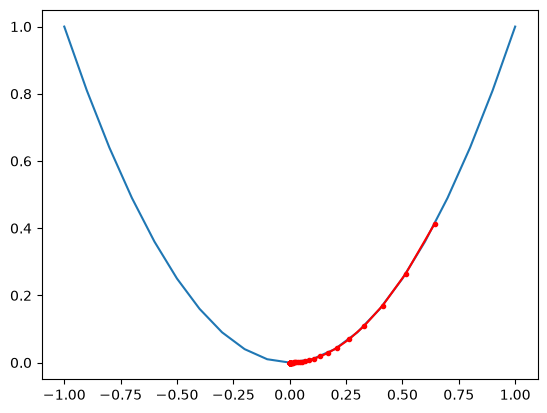

In [58]:
#Grafica de la solucion
#Calculamos la funcion y=f(x)
x = np.arange(bounds[0,0], bounds[0,1]+0.1, 0.1)
y = objetivo(x)
# Graficamos la funcion
pyplot.plot(x, y)
# Graficamos la solucion
pyplot.plot(solutions, score, '.-', color='red')
pyplot.show()



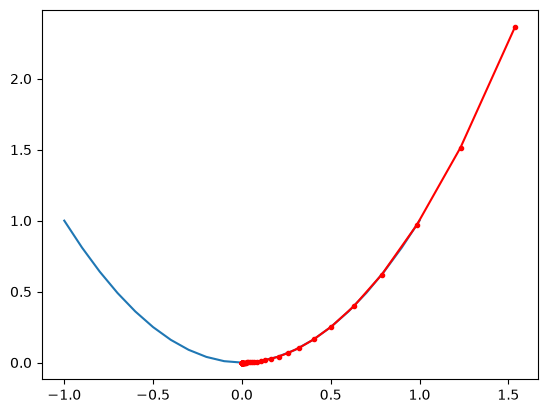

In [59]:
#Analicemos el efecto de la longitud del paso
##############
bounds = np.asarray([[-2.0, 2.0]])
solutions, scores = gradiente_descendente(objetivo, derivada, bounds, n_iter, step_size, False)
pyplot.plot(x,y)
pyplot.plot(solutions, scores, '.-', color='red')
pyplot.show()




#### (B) Uso de gradiente descendiente para solucionar un problema de regresion lineal

Text(0, 0.5, 'y')

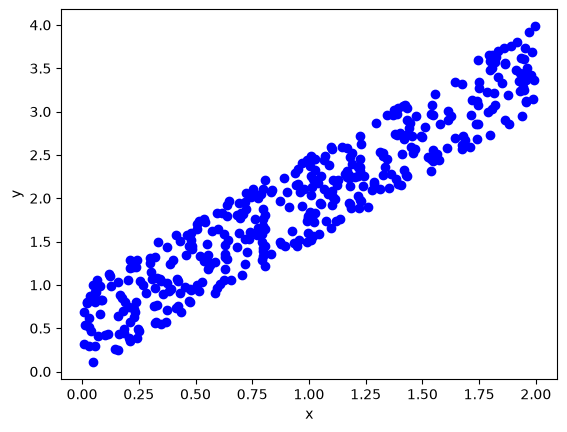

In [60]:
# Vamos a generar datos con ruido gaussiano
import numpy as np
import matplotlib.pyplot as plt

X = 2*np.random.rand(400,1)
y = 1.5*X + np.random.rand(400,1)
plt.scatter(X,y,c='blue',marker='o')
plt.xlabel('x')
plt.ylabel('y')


In [61]:
#Organizamos los datos para realizar el calculo vectorial
#Debemos agregar una columna de 1s a los datos

n_rows = X.shape[0]
ones = np.ones((n_rows,1))
X = np.concatenate((ones,X),axis=1)
X.shape

(400, 2)

Primero, debemos definir la funcion de costo. En este caso vamos usar el error cuadratico medio como funcion a minimizar:
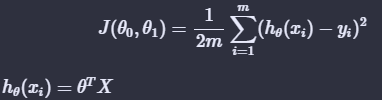

In [62]:
def compute_cost(X, y, theta=np.array([[0],[0]])):
    #Determinamos m: numero de muestras
    m = len(y)
    #Organizamos las dimensiones de la solucion
    theta=theta.reshape(2,1)
    # Calculamos y_hat
    h_x = np.dot(X,theta)
    # Calculamos el error cuadratico
    error_term = sum((h_x-y)**2)
    # Dividimos por 2*m
    loss = error_term/(2*m)
    return loss

In [63]:
def gradient_descent(X, y, theta=np.array([[0],[0]]),
                    step_size=0.01, n_iter=1500):
#Inicializacion de parametros
    m = len(y)
    J_history = []
    theta0_history = []
    theta1_history = []
    theta = theta.reshape(2,1)


    for i in range(n_iter):
        #Calculo de la derivada producto punto 
        error = np.dot(X,theta) - y 
        
        # derivadas
        term0 = (1/m)*sum(error*X[:,0].reshape(m,1))
        term1 = (1/m)*sum(error*X[:,1].reshape(m,1))
        
        #Alctualziacion de theta
        gradiente = np.array([[term0],[term1]])
        theta = theta - step_size*gradiente.reshape(2,1)

        #Guardar valores
        theta0_history.append(theta[0].tolist()[0])
        theta1_history.append(theta[1].tolist()[0])
        J_history.append(compute_cost(X,y,theta).tolist()[0])

    return (theta, J_history, theta0_history, theta1_history)

In [65]:
#Prueba de la funcion

n_iter=1500
theta_init=np.array([[1],[1]])
step_size=0.05
theta, J_history, theta0_history, theta1_history = gradient_descent(X,y, theta_init,
                                                                   step_size, n_iter)




In [66]:
#Parametros estimados
print(theta)

[[0.51575048]
 [1.48637613]]


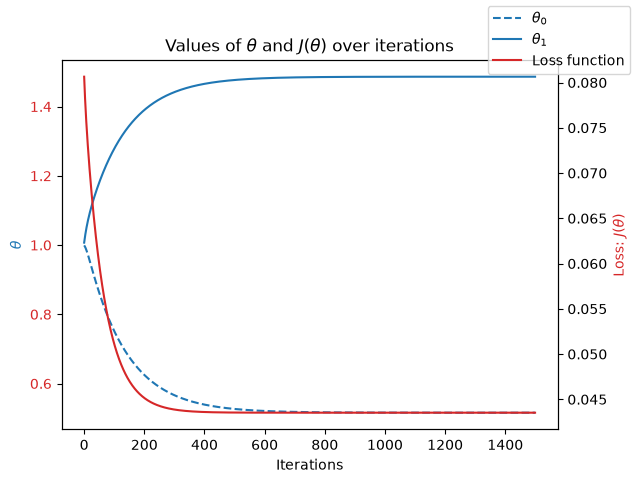

In [67]:
fig, ax1 = plt.subplots()

# plot thetas over time
color='tab:blue'
ax1.plot(theta0_history, label='$\\theta_{0}$', linestyle='--', color=color)
ax1.plot(theta1_history, label='$\\theta_{1}$', linestyle='-', color=color)
# ax1.legend()
ax1.set_xlabel('Iterations'); ax1.set_ylabel('$\\theta$', color=color);
ax1.tick_params(axis='y', labelcolor=color)

# plot loss function over time
color='tab:red'
ax2 = ax1.twinx()
ax2.plot(J_history, label='Loss function', color=color)
ax2.set_title('Values of $\\theta$ and $J(\\theta)$ over iterations')
ax2.set_ylabel('Loss: $J(\\theta)$', color=color)
ax1.tick_params(axis='y', labelcolor=color)

# ax2.legend();
fig.legend();

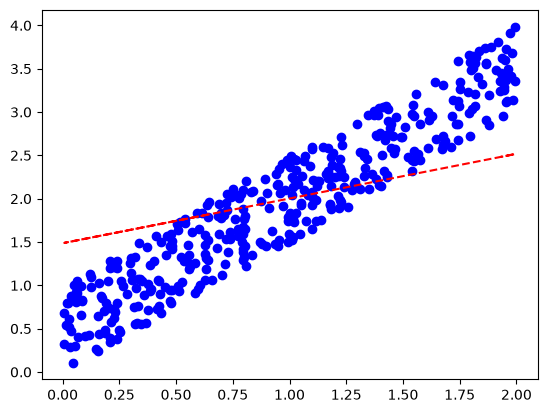

In [68]:
#Grafica de la funcion lineal estimada
plt.scatter(X[:,1],y,c='blue',marker='o')
y_vals = theta[1]+theta[0]*X[:,1]
plt.plot(X[:,1],y_vals,'--r')